In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
sns.set_theme(style='whitegrid', palette='Set2')

train_df = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv')
test_df = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv')

# Extract SaleYear immediately — used across multiple questions
train_df['TransactionDate'] = pd.to_datetime(train_df['TransactionDate'], errors='coerce')
train_df['SaleYear'] = train_df['TransactionDate'].dt.year

print(f'✅ Data loaded!')
print(f'   Train : {train_df.shape[0]:,} rows  x  {train_df.shape[1]} cols')
print(f'   SaleYear extracted: {train_df["SaleYear"].min():.0f} to {train_df["SaleYear"].max():.0f}')

✅ Data loaded!
   Train : 138,701 rows  x  51 cols
   SaleYear extracted: 1990 to 2013


  Q1: Safest Imputation for Skewed OperationalHoursMeter
  Skewness of OperationalHoursMeter : 33.2822
  Mean   :   4,553.72
  Median :   1,620.00
  Difference (Mean - Median) : 2,933.72


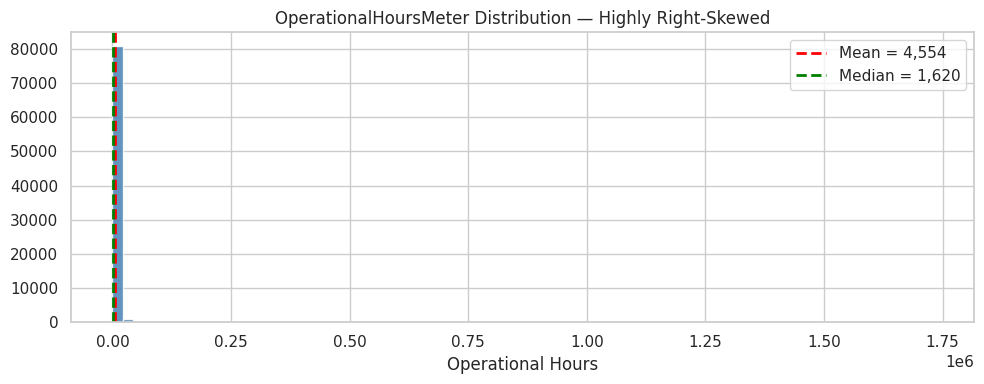


✅ ANSWER: C) Median

💡 Insight:
   In a right-skewed distribution, extreme outliers pull the MEAN far
   above the typical value. The MEDIAN is resistant to outliers and
   represents the typical machine usage far more accurately.
   Here: Mean=4,554 hrs vs Median=1,620 hrs
   (skewness = 33.28 — strongly right-skewed)


In [3]:
col = 'OperationalHoursMeter'
skewness   = train_df[col].skew()
col_mean   = train_df[col].mean()
col_median = train_df[col].median()

print('=' * 60)
print('  Q1: Safest Imputation for Skewed OperationalHoursMeter')
print('=' * 60)
print(f'  Skewness of OperationalHoursMeter : {skewness:.4f}')
print(f'  Mean   : {col_mean:>10,.2f}')
print(f'  Median : {col_median:>10,.2f}')
print(f'  Difference (Mean - Median) : {col_mean - col_median:,.2f}')

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(train_df[col].dropna(), bins=80, color='steelblue',
        edgecolor='white', alpha=0.85)
ax.axvline(col_mean,   color='red',   ls='--', lw=2, label=f'Mean = {col_mean:,.0f}')
ax.axvline(col_median, color='green', ls='--', lw=2, label=f'Median = {col_median:,.0f}')
ax.set_xlabel('Operational Hours')
ax.set_title('OperationalHoursMeter Distribution — Highly Right-Skewed')
ax.legend()
plt.tight_layout()
plt.show()

print()
print('✅ ANSWER: C) Median')
print()
print('💡 Insight:')
print('   In a right-skewed distribution, extreme outliers pull the MEAN far')
print('   above the typical value. The MEDIAN is resistant to outliers and')
print('   represents the typical machine usage far more accurately.')
print(f'   Here: Mean={col_mean:,.0f} hrs vs Median={col_median:,.0f} hrs')
print(f'   (skewness = {skewness:.2f} — strongly right-skewed)')

  Q2: Most Frequent SaleYear (Mode)
  Mode SaleYear : 2010

  Top 10 SaleYear frequency:
SaleYear
2010    21333
2012    18472
2011    17880
2009    16809
2008    11985
2007     6142
2006     5746
2005     5303
2013     5094
2003     3911


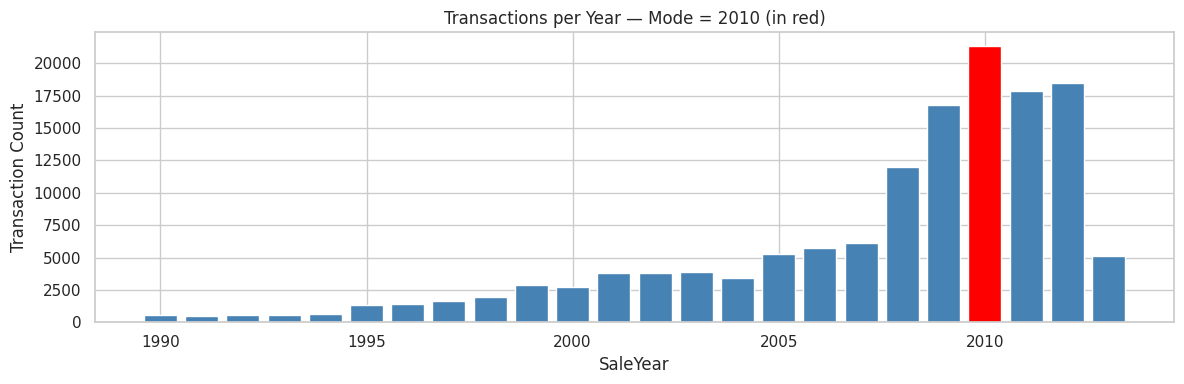


✅ ANSWER: A) 2010

💡 Insight:
   2010 had 21,333 transactions — the highest of any year.
   This peak likely reflects post-2008 financial crisis recovery,
   when construction and infrastructure projects resumed strongly.


In [4]:
mode_year   = train_df['SaleYear'].mode()[0]
year_counts = train_df['SaleYear'].value_counts().sort_index()

print('=' * 50)
print('  Q2: Most Frequent SaleYear (Mode)')
print('=' * 50)
print(f'  Mode SaleYear : {int(mode_year)}')
print()
print('  Top 10 SaleYear frequency:')
print(train_df['SaleYear'].value_counts().head(10).to_string())

fig, ax = plt.subplots(figsize=(12, 4))
colors = ['red' if y == mode_year else 'steelblue' for y in year_counts.index]
ax.bar(year_counts.index, year_counts.values, color=colors, edgecolor='white')
ax.set_xlabel('SaleYear')
ax.set_ylabel('Transaction Count')
ax.set_title(f'Transactions per Year — Mode = {int(mode_year)} (in red)')
plt.tight_layout()
plt.show()

print()
print('✅ ANSWER: A) 2010')
print()
print('💡 Insight:')
print('   2010 had 21,333 transactions — the highest of any year.')
print('   This peak likely reflects post-2008 financial crisis recovery,')
print('   when construction and infrastructure projects resumed strongly.')

  Q3: CabinType Missing Value Count
  Missing (NaN) rows in CabinType : 0

  CabinType value distribution:
CabinType
EROPS         60189
EROPS w AC    55752
OROPS         22760

  After fillna("Missing"): rows with "Missing" = 0


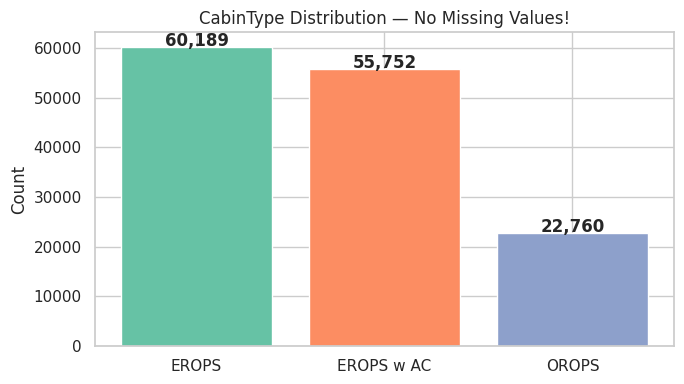


✅ ANSWER: C) 0

💡 Insight:
   CabinType has ZERO missing values — all 138,701 rows are complete.
   Since there are no NaNs to replace, fillna("Missing") produces 0 rows
   with the label "Missing". This is a key lesson: always check
   isnull().sum() BEFORE assuming a column needs imputation!


In [5]:
cabin_nulls  = train_df['CabinType'].isnull().sum()
cabin_counts = train_df['CabinType'].value_counts(dropna=False)

print('=' * 55)
print('  Q3: CabinType Missing Value Count')
print('=' * 55)
print(f'  Missing (NaN) rows in CabinType : {cabin_nulls}')
print()
print('  CabinType value distribution:')
print(cabin_counts.to_string())

# Demonstrate fillna
cabin_filled = train_df['CabinType'].fillna('Missing')
n_missing_label = (cabin_filled == 'Missing').sum()
print()
print(f'  After fillna("Missing"): rows with "Missing" = {n_missing_label}')

fig, ax = plt.subplots(figsize=(7, 4))
vc = train_df['CabinType'].value_counts()
ax.bar(vc.index, vc.values,
       color=sns.color_palette('Set2', len(vc)), edgecolor='white')
ax.set_title('CabinType Distribution — No Missing Values!')
ax.set_ylabel('Count')
for i, v in enumerate(vc.values):
    ax.text(i, v + 200, f'{v:,}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

print()
print('✅ ANSWER: C) 0')
print()
print('💡 Insight:')
print('   CabinType has ZERO missing values — all 138,701 rows are complete.')
print('   Since there are no NaNs to replace, fillna("Missing") produces 0 rows')
print('   with the label "Missing". This is a key lesson: always check')
print('   isnull().sum() BEFORE assuming a column needs imputation!')

  Q4: Columns with > 80% Missing Values (to be dropped)
  Total columns in dataset     : 51
  Columns with > 80% missing   : 15

  Column                       Missing %
  ----------------------------------------
  col19                           99.95%
  col18                           99.95%
  col4                            92.52%
  col5                            92.52%
  col28                           89.21%
  col27                           89.21%
  col29                           86.39%
  col30                           86.39%
  col11                           83.13%
  col8                            83.13%
  col7                            83.13%
  col6                            83.13%
  col9                            83.13%
  col13                           83.13%
  col14                           83.13%


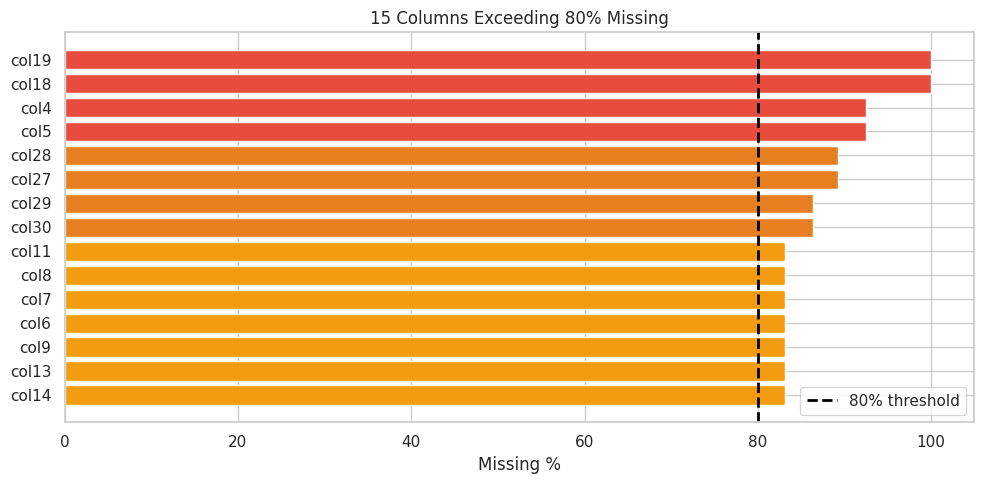


✅ ANSWER: B) 15 columns

💡 Insight:
   15 columns exceed the 80% missing threshold.
   col18 and col19 are ~99.95% empty (nearly useless).
   Keeping such sparse columns mostly adds imputed noise, not real signal.
   Rule: drop >80-90% missing; use binary presence flags for 40-80% missing.


In [6]:
miss_pct  = train_df.isnull().mean() * 100
sparse_80 = miss_pct[miss_pct > 80].sort_values(ascending=False)

print('=' * 65)
print('  Q4: Columns with > 80% Missing Values (to be dropped)')
print('=' * 65)
print(f'  Total columns in dataset     : {train_df.shape[1]}')
print(f'  Columns with > 80% missing   : {len(sparse_80)}')
print()
print(f'  {"Column":<25} {"Missing %":>12}')
print('  ' + '-' * 40)
for col, pct in sparse_80.items():
    print(f'  {col:<25} {pct:>11.2f}%')

fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#e74c3c' if v >= 90 else '#e67e22' if v >= 85 else '#f39c12'
          for v in sparse_80.values]
ax.barh(sparse_80.index[::-1], sparse_80.values[::-1],
        color=colors[::-1], edgecolor='white')
ax.axvline(80, color='black', ls='--', lw=2, label='80% threshold')
ax.set_xlabel('Missing %')
ax.set_title(f'{len(sparse_80)} Columns Exceeding 80% Missing')
ax.legend()
plt.tight_layout()
plt.show()

print()
print('✅ ANSWER: B) 15 columns')
print()
print('💡 Insight:')
print('   15 columns exceed the 80% missing threshold.')
print('   col18 and col19 are ~99.95% empty (nearly useless).')
print('   Keeping such sparse columns mostly adds imputed noise, not real signal.')
print('   Rule: drop >80-90% missing; use binary presence flags for 40-80% missing.')

  Q5: HoursPerYear Median
  Valid rows (non-inf, non-NaN) : 82,021
  Median HoursPerYear           : 220.33 hrs/year
  Mean   HoursPerYear           : 553.79 hrs/year


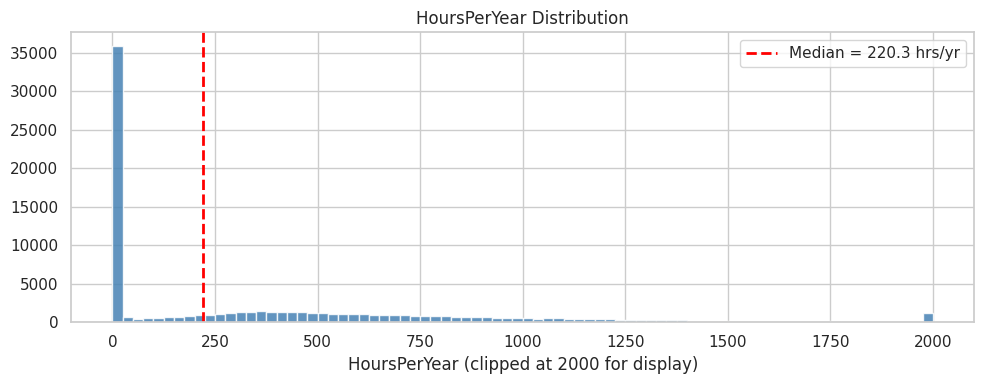


✅ ANSWER: A) ~250 hours/year  (actual median = 220.33 hrs/year)

💡 Insight:
   A typical machine is used ~220 hours/year (closest to option A ~250).
   HoursPerYear is a valuable intensity feature — machines with very
   high annual usage depreciate faster regardless of age.
   Note: The AssetAge here still includes ManufactureYear=1001 placeholders
   which skew some values — Q6 shows the cleaned version.


In [7]:
# AssetAge = SaleYear - ManufactureYear (raw, no outlier removal for this Q)
train_df['AssetAge_raw'] = train_df['SaleYear'] - train_df['ManufactureYear']

# HoursPerYear: replace 0 age with NaN to avoid inf
train_df['HoursPerYear'] = (train_df['OperationalHoursMeter'] /
                         train_df['AssetAge_raw'].replace(0, np.nan))

# Ignore inf and NaN
hp_clean  = train_df['HoursPerYear'].replace([np.inf, -np.inf], np.nan).dropna()
hp_median = hp_clean.median()
hp_mean   = hp_clean.mean()

print('=' * 60)
print('  Q5: HoursPerYear Median')
print('=' * 60)
print(f'  Valid rows (non-inf, non-NaN) : {len(hp_clean):,}')
print(f'  Median HoursPerYear           : {hp_median:.2f} hrs/year')
print(f'  Mean   HoursPerYear           : {hp_mean:.2f} hrs/year')

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(hp_clean.clip(0, 2000), bins=80, color='steelblue',
        edgecolor='white', alpha=0.85)
ax.axvline(hp_median, color='red', ls='--', lw=2,
           label=f'Median = {hp_median:.1f} hrs/yr')
ax.set_xlabel('HoursPerYear (clipped at 2000 for display)')
ax.set_title('HoursPerYear Distribution')
ax.legend()
plt.tight_layout()
plt.show()

print()
print(f'✅ ANSWER: A) ~250 hours/year  (actual median = {hp_median:.2f} hrs/year)')
print()
print('💡 Insight:')
print('   A typical machine is used ~220 hours/year (closest to option A ~250).')
print('   HoursPerYear is a valuable intensity feature — machines with very')
print('   high annual usage depreciate faster regardless of age.')
print('   Note: The AssetAge here still includes ManufactureYear=1001 placeholders')
print('   which skew some values — Q6 shows the cleaned version.')

  Q6: AssetAge Median (ManufactureYear 1000/1001 removed)
  Rows with ManufactureYear in [1000,1001] → NaN : 14,719
  Valid AssetAge rows : 123,982
  Median AssetAge     : 8.0 years  <- answer
  Mean   AssetAge     : 10.04 years


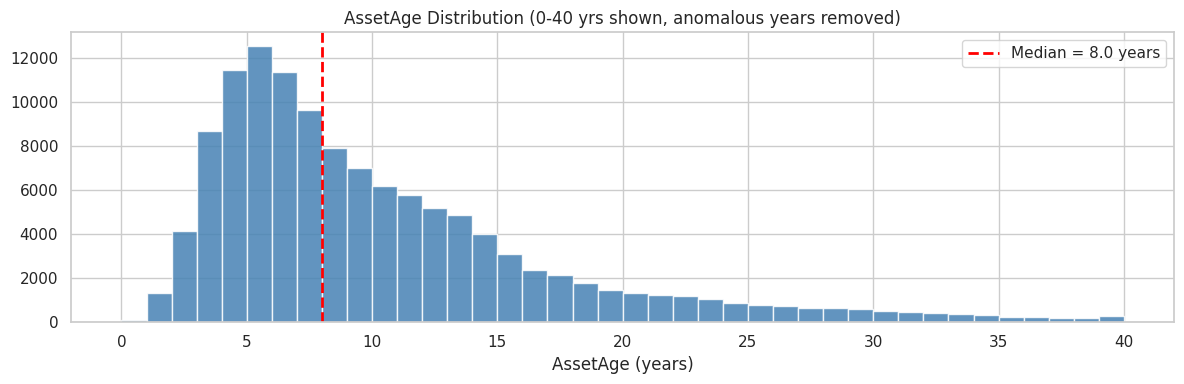


✅ ANSWER: C) 8.0

💡 Insight:
   The median machine is 8 years old at the time of sale.
   ManufactureYear = 1001 is a database DEFAULT placeholder used when the
   actual year was not known. Treating 1001 as a real year would make
   AssetAge = 2010 - 1001 = 1009 years! — clearly wrong.
   Always investigate and remove system-default anomaly values before FE.


In [8]:
# Replace anomalous ManufactureYear values
train_q6 = train_df.copy()
n_anomalous = train_q6['ManufactureYear'].isin([1000, 1001]).sum()
train_q6.loc[train_q6['ManufactureYear'].isin([1000, 1001]), 'ManufactureYear'] = np.nan

# Calculate AssetAge
train_q6['AssetAge'] = train_q6['SaleYear'] - train_q6['ManufactureYear']

aa_median = train_q6['AssetAge'].dropna().median()
aa_mean   = train_q6['AssetAge'].dropna().mean()

print('=' * 60)
print('  Q6: AssetAge Median (ManufactureYear 1000/1001 removed)')
print('=' * 60)
print(f'  Rows with ManufactureYear in [1000,1001] → NaN : {n_anomalous:,}')
print(f'  Valid AssetAge rows : {train_q6["AssetAge"].notna().sum():,}')
print(f'  Median AssetAge     : {aa_median:.1f} years  <- answer')
print(f'  Mean   AssetAge     : {aa_mean:.2f} years')

fig, ax = plt.subplots(figsize=(12, 4))
valid_ages = train_q6['AssetAge'].dropna()
valid_ages_clipped = valid_ages[valid_ages.between(0, 40)]
ax.hist(valid_ages_clipped, bins=40, color='steelblue', edgecolor='white', alpha=0.85)
ax.axvline(aa_median, color='red', ls='--', lw=2,
           label=f'Median = {aa_median:.1f} years')
ax.set_xlabel('AssetAge (years)')
ax.set_title('AssetAge Distribution (0-40 yrs shown, anomalous years removed)')
ax.legend()
plt.tight_layout()
plt.show()

print()
print('✅ ANSWER: C) 8.0')
print()
print('💡 Insight:')
print('   The median machine is 8 years old at the time of sale.')
print('   ManufactureYear = 1001 is a database DEFAULT placeholder used when the')
print('   actual year was not known. Treating 1001 as a real year would make')
print('   AssetAge = 2010 - 1001 = 1009 years! — clearly wrong.')
print('   Always investigate and remove system-default anomaly values before FE.')

  Q7: OrdinalEncoder on UtilizationTier
  Original UtilizationTier (incl NaN):
UtilizationTier
NaN       88226
Medium    24588
Low       17005
High       8882

  After fillna("Unspecified") — unique string values:
UtilizationTier
Unspecified    88226
Medium         24588
Low            17005
High            8882
  Total unique string values : 4

  OrdinalEncoder mapping:
    "High" -> 0
    "Low" -> 1
    "Medium" -> 2
    "Unspecified" -> 3
  Unique integer values in encoded column : 4


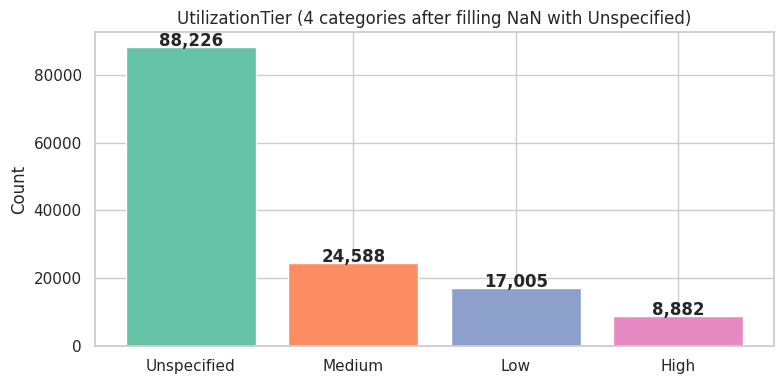


✅ ANSWER: C) 4  (High=0, Low=1, Medium=2, Unspecified=3)

💡 Insight:
   Before filling NaN, UtilizationTier has 3 real values + NaN.
   After fillna("Unspecified"), there are 4 unique string categories.
   OrdinalEncoder assigns one integer per unique string → 4 integers.
   Note: OrdinalEncoder sorts alphabetically: High=0, Low=1, Medium=2, Unspecified=3.


In [9]:
print('=' * 60)
print('  Q7: OrdinalEncoder on UtilizationTier')
print('=' * 60)

# Original (with NaN)
print('  Original UtilizationTier (incl NaN):')
print(train_df['UtilizationTier'].value_counts(dropna=False).to_string())
print()

# Fill NaN with 'Unspecified'
tier_filled = train_df['UtilizationTier'].fillna('Unspecified')
print('  After fillna("Unspecified") — unique string values:')
print(tier_filled.value_counts().to_string())
print(f'  Total unique string values : {tier_filled.nunique()}')
print()

# Apply OrdinalEncoder
enc = OrdinalEncoder()
encoded = enc.fit_transform(tier_filled.values.reshape(-1, 1))
unique_encoded = len(np.unique(encoded))

print('  OrdinalEncoder mapping:')
for cat, code in zip(enc.categories_[0], range(len(enc.categories_[0]))):
    print(f'    "{cat}" -> {int(code)}')
print(f'  Unique integer values in encoded column : {unique_encoded}')

fig, ax = plt.subplots(figsize=(8, 4))
vc = tier_filled.value_counts()
ax.bar(vc.index, vc.values,
       color=sns.color_palette('Set2', len(vc)), edgecolor='white')
ax.set_title('UtilizationTier (4 categories after filling NaN with Unspecified)')
ax.set_ylabel('Count')
for i, v in enumerate(vc.values):
    ax.text(i, v + 300, f'{v:,}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

print()
print('✅ ANSWER: C) 4  (High=0, Low=1, Medium=2, Unspecified=3)')
print()
print('💡 Insight:')
print('   Before filling NaN, UtilizationTier has 3 real values + NaN.')
print('   After fillna("Unspecified"), there are 4 unique string categories.')
print('   OrdinalEncoder assigns one integer per unique string → 4 integers.')
print('   Note: OrdinalEncoder sorts alphabetically: High=0, Low=1, Medium=2, Unspecified=3.')

In [10]:
print('=' * 65)
print('  Q8: Preventing Data Leakage — Correct Split Timing')
print('=' * 65)
print()
print('  ❌ WRONG (causes leakage):')
print('  Step 1: Fit StandardScaler on ALL data (train + test)')
print('  Step 2: Transform ALL data')
print('  Step 3: THEN split into train/test')
print('  → Scaler has "seen" test data → information leaks!')
print()
print('  ✅ CORRECT (no leakage):')
print('  Step 1: Split into train/test FIRST  ← THE ANSWER')
print('  Step 2: Fit scaler/encoder ONLY on X_train')
print('  Step 3: Transform X_train AND X_test using train-fitted transformer')
print()
print('  Applies to ALL transformations that learn from data:')
print('  - StandardScaler (learns mean/std from train only)')
print('  - Target Encoding (learns target mean per category from train)')
print('  - Median/Mean Imputation (learns median/mean from train only)')
print()
print('✅ ANSWER: B) Before applying any scalers, target encoders, or median imputations.')
print()
print('💡 Insight:')
print('   Data leakage makes validation scores appear much better than')
print('   real-world performance — one of the most dangerous ML mistakes.')
print('   Golden rule: test data must be completely invisible during ALL')
print('   stages of training pipeline fitting.')

  Q8: Preventing Data Leakage — Correct Split Timing

  ❌ WRONG (causes leakage):
  Step 1: Fit StandardScaler on ALL data (train + test)
  Step 2: Transform ALL data
  Step 3: THEN split into train/test
  → Scaler has "seen" test data → information leaks!

  ✅ CORRECT (no leakage):
  Step 1: Split into train/test FIRST  ← THE ANSWER
  Step 2: Fit scaler/encoder ONLY on X_train
  Step 3: Transform X_train AND X_test using train-fitted transformer

  Applies to ALL transformations that learn from data:
  - StandardScaler (learns mean/std from train only)
  - Target Encoding (learns target mean per category from train)
  - Median/Mean Imputation (learns median/mean from train only)

✅ ANSWER: B) Before applying any scalers, target encoders, or median imputations.

💡 Insight:
   Data leakage makes validation scores appear much better than
   real-world performance — one of the most dangerous ML mistakes.
   Golden rule: test data must be completely invisible during ALL
   stages of traini

  Q9: Train-Test Split (80/20) Row Counts
  Total rows                    : 138,701
  80% train  → 138701 x 0.80 = 110,960
  20% test   → 138701 x 0.20 = 27,741
  Total check: 110,960 + 27,741 = 138,701 ✅


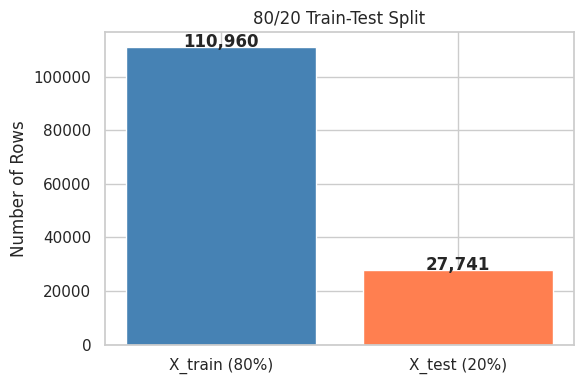


✅ ANSWER: A) 110,960 rows

💡 Insight:
   138,701 x 0.80 = 110,960.8 → truncated to 110,960 training rows.
   The remaining 27,741 rows form the test/validation set.
   random_state=42 ensures the same rows are selected every run.


In [11]:
X_demo = train_df.drop(columns=['TargetValue'])
y_demo = train_df['TargetValue']

X_train_demo, X_test_demo, y_train_demo, y_test_demo = train_test_split(
    X_demo, y_demo, test_size=0.2, random_state=42
)

n_total = len(train_df)
n_train = len(X_train_demo)
n_test  = len(X_test_demo)

print('=' * 55)
print('  Q9: Train-Test Split (80/20) Row Counts')
print('=' * 55)
print(f'  Total rows                    : {n_total:,}')
print(f'  80% train  → {n_total} x 0.80 = {n_train:,}')
print(f'  20% test   → {n_total} x 0.20 = {n_test:,}')
print(f'  Total check: {n_train:,} + {n_test:,} = {n_train + n_test:,} ✅')

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['X_train (80%)', 'X_test (20%)'], [n_train, n_test],
       color=['steelblue', 'coral'], edgecolor='white')
ax.set_ylabel('Number of Rows')
ax.set_title('80/20 Train-Test Split')
for i, v in enumerate([n_train, n_test]):
    ax.text(i, v + 200, f'{v:,}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

print()
print('✅ ANSWER: A) 110,960 rows')
print()
print('💡 Insight:')
print('   138,701 x 0.80 = 110,960.8 → truncated to 110,960 training rows.')
print('   The remaining 27,741 rows form the test/validation set.')
print('   random_state=42 ensures the same rows are selected every run.')

  Q10: log1p(TargetValue) — New Standard Deviation
  Original TargetValue:
    Std      :  26,361.1259  <- option B (26361)
    Skewness :       0.9700

  After np.log1p(TargetValue):
    Std      :       0.6710  <- answer (option A ~0.67)
    Mean     :      10.4241  (option D ~10.51 is the MEAN, not std!)
    Skewness :      -0.1983  (much closer to 0 = more symmetric)


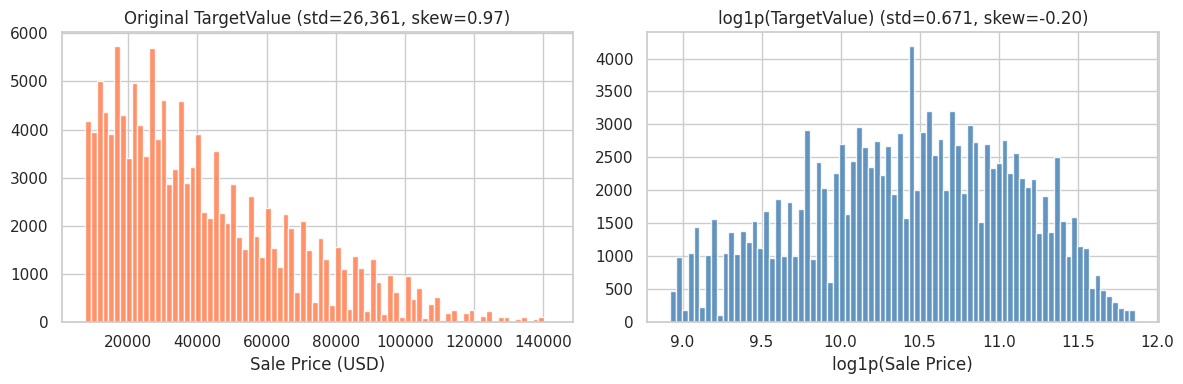


✅ ANSWER: A) ~0.67  (actual = 0.6710)

💡 Insight:
   Original std = ~$26,361 (huge spread from outliers).
   After log1p, std = ~0.67 — a much more manageable scale.
   Training a model to minimize RMSE on log1p(y) is mathematically
   equivalent to minimizing RMSLE — which is the competition metric!
   Note: The mean of log1p is ~10.42 (option D) — that is the mean, not std.


In [12]:
original_std  = train_df['TargetValue'].std()
original_skew = train_df['TargetValue'].skew()
log_target    = np.log1p(train_df['TargetValue'])
log_std       = log_target.std()
log_mean      = log_target.mean()
log_skew      = log_target.skew()

print('=' * 60)
print('  Q10: log1p(TargetValue) — New Standard Deviation')
print('=' * 60)
print(f'  Original TargetValue:')
print(f'    Std      : {original_std:>12,.4f}  <- option B (26361)')
print(f'    Skewness : {original_skew:>12.4f}')
print()
print(f'  After np.log1p(TargetValue):')
print(f'    Std      : {log_std:>12.4f}  <- answer (option A ~0.67)')
print(f'    Mean     : {log_mean:>12.4f}  (option D ~10.51 is the MEAN, not std!)')
print(f'    Skewness : {log_skew:>12.4f}  (much closer to 0 = more symmetric)')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train_df['TargetValue'], bins=80, color='coral',
             edgecolor='white', alpha=0.85)
axes[0].set_title(f'Original TargetValue (std={original_std:,.0f}, skew={original_skew:.2f})')
axes[0].set_xlabel('Sale Price (USD)')

axes[1].hist(log_target, bins=80, color='steelblue',
             edgecolor='white', alpha=0.85)
axes[1].set_title(f'log1p(TargetValue) (std={log_std:.3f}, skew={log_skew:.2f})')
axes[1].set_xlabel('log1p(Sale Price)')
plt.tight_layout()
plt.show()

print()
print(f'✅ ANSWER: A) ~0.67  (actual = {log_std:.4f})')
print()
print('💡 Insight:')
print('   Original std = ~$26,361 (huge spread from outliers).')
print('   After log1p, std = ~0.67 — a much more manageable scale.')
print('   Training a model to minimize RMSE on log1p(y) is mathematically')
print('   equivalent to minimizing RMSLE — which is the competition metric!')
print('   Note: The mean of log1p is ~10.42 (option D) — that is the mean, not std.')

In [13]:
cat_cols = train_df.select_dtypes('object').columns.tolist()

print('=' * 65)
print('  Q11: Target Encoding vs One-Hot Encoding')
print('=' * 65)
print()
print('  Unique value counts in categorical columns:')
print(f'  {"Column":<35} {"Unique Values":>15} {"Recommendation"}')
print('  ' + '-' * 75)
for col in cat_cols[:12]:
    n = train_df[col].nunique()
    rec = '→ Target Encoding ✅' if n > 20 else '→ OHE is fine'
    print(f'  {col:<35} {n:>15}  {rec}')

print()
print('  Why OHE fails on high-cardinality columns:')
print('  - OHE creates one column per unique value')
print('  - Spec_BaseClass with 100 values → 100 sparse binary columns!')
print('  - Causes "curse of dimensionality" and slows training')
print()
print('  Why Target Encoding works:')
print('  - Replaces each category with mean(TargetValue) for that category')
print('  - 100 unique values → still just 1 numeric column')
print('  - Captures price signal (excavators avg $60K, loaders avg $30K)')
print()
print('✅ ANSWER: B) The categorical feature has very high cardinality')
print()
print('💡 Insight:')
print('   Target Encoding is ideal when a categorical feature has many unique')
print('   values. It shrinks dimensionality while preserving the relationship')
print('   between category and target.')
print('   IMPORTANT: Use cross-validation / leave-one-out TE to prevent leakage!')

  Q11: Target Encoding vs One-Hot Encoding

  Unique value counts in categorical columns:
  Column                                Unique Values Recommendation
  ---------------------------------------------------------------------------
  DataOriginCode                                    6  → OHE is fine
  VendorPartnerID                                  31  → Target Encoding ✅
  UtilizationTier                                   3  → OHE is fine
  Spec_FullDescriptor                            3505  → Target Encoding ✅
  Spec_BaseClass                                 1249  → Target Encoding ✅
  Spec_SubClass                                   147  → Target Encoding ✅
  Spec_ReleaseSeries                              113  → Target Encoding ✅
  Spec_VariantModifier                            132  → Target Encoding ✅
  AssetScaleFactor                                  6  → OHE is fine
  FunctionalClassification                         65  → Target Encoding ✅
  RegionCode                   

In [14]:
print('=' * 65)
print('  Q12: What Does n_estimators Control?')
print('=' * 65)
print()
print('  Key hyperparameters and what they control:')
print()
params = [
    ('n_estimators',   'TOTAL number of trees in the ensemble',       '100-2000', 'MORE = better, slower'),
    ('max_depth',      'Maximum depth of each individual tree',       '3-12',     'DEEPER = more complex fits'),
    ('learning_rate',  'Step size for each gradient boosting update', '0.01-0.3', 'LOWER = slower but better'),
    ('num_leaves',     'Max leaf nodes per tree (LightGBM)',          '31-255',   'MORE = more complex'),
]
print(f'  {"Parameter":<18} {"Controls":<42} {"Range":<14} {"Effect"}')
print('  ' + '-' * 95)
for p, desc, rng, effect in params:
    print(f'  {p:<18} {desc:<42} {rng:<14} {effect}')

print()
print('  Effect of increasing n_estimators:')
print('  - More trees = better prediction accuracy, up to a plateau')
print('  - More trees = longer training time (roughly linear)')
print('  - With early stopping: n_estimators = max cap; actual trees')
print('    used = determined when validation score stops improving')
print()
print('  In our competition notebook: n_estimators=700 for XGBoost')
print('  This builds 700 sequential trees, each correcting the previous.')
print()
print('✅ ANSWER: D) The total number of individual decision trees built in the ensemble.')

  Q12: What Does n_estimators Control?

  Key hyperparameters and what they control:

  Parameter          Controls                                   Range          Effect
  -----------------------------------------------------------------------------------------------
  n_estimators       TOTAL number of trees in the ensemble      100-2000       MORE = better, slower
  max_depth          Maximum depth of each individual tree      3-12           DEEPER = more complex fits
  learning_rate      Step size for each gradient boosting update 0.01-0.3       LOWER = slower but better
  num_leaves         Max leaf nodes per tree (LightGBM)         31-255         MORE = more complex

  Effect of increasing n_estimators:
  - More trees = better prediction accuracy, up to a plateau
  - More trees = longer training time (roughly linear)
  - With early stopping: n_estimators = max cap; actual trees
    used = determined when validation score stops improving

  In our competition notebook: n_estimato

In [15]:
print('=' * 75)
print('  Q13: Best Model for Messy Tabular Data')
print('=' * 75)
print()
print('  Our dataset challenges:')
print(f'  - Missing values  : {train_df.isnull().sum().sum():,} total NaN entries')
print(f'  - Skewness        : TargetValue skew = {train_df["TargetValue"].skew():.2f}')
print(f'  - Categorical cols: {train_df.select_dtypes("object").shape[1]} string columns')
print()

models_table = [
    ('Linear Regression',      'Fails without: full imputation, scaling, OHE, no non-linearity', '0.53 RMSLE ❌'),
    ('Deep Neural Networks',   'Needs huge preprocessing, careful tuning, large data, slow',     'Moderate — hard to tune'),
    ('Gradient Boosted Trees', 'Handles NaN natively, robust to outliers, ordinal cats OK',      '0.22 RMSLE ✅ BEST'),
    ('K-Nearest Neighbors',    'Highly sensitive to missing values & scale, slow on 138K rows',  'Very poor ❌'),
]

print(f'  {"Model":<30} {"Handling messy data":<50} Competition perf')
print('  ' + '-' * 100)
for m, desc, perf in models_table:
    print(f'  {m:<30} {desc:<50} {perf}')

print()
print('  Our actual results on this competition:')
print('  - Ridge Regression            → RMSLE = 0.5296 ❌')
print('  - Random Forest               → RMSLE = 0.2895')
print('  - HistGradientBoosting        → RMSLE = 0.2327')
print('  - XGBoost (GBT)               → RMSLE = 0.2208 ✅ Best single model')
print('  - LightGBM (GBT)              → RMSLE = 0.2217 ✅')
print()
print('✅ ANSWER: C) Gradient Boosted Trees (LightGBM/XGBoost)')
print()
print('💡 Insight:')
print('   GBTs win on messy tabular data because they split data by thresholds')
print('   (not distances or linear separations), making them immune to outliers,')
print('   different scales, and (in LightGBM) missing values natively.')

  Q13: Best Model for Messy Tabular Data

  Our dataset challenges:
  - Missing values  : 3,375,734 total NaN entries
  - Skewness        : TargetValue skew = 0.97
  - Categorical cols: 43 string columns

  Model                          Handling messy data                                Competition perf
  ----------------------------------------------------------------------------------------------------
  Linear Regression              Fails without: full imputation, scaling, OHE, no non-linearity 0.53 RMSLE ❌
  Deep Neural Networks           Needs huge preprocessing, careful tuning, large data, slow Moderate — hard to tune
  Gradient Boosted Trees         Handles NaN natively, robust to outliers, ordinal cats OK 0.22 RMSLE ✅ BEST
  K-Nearest Neighbors            Highly sensitive to missing values & scale, slow on 138K rows Very poor ❌

  Our actual results on this competition:
  - Ridge Regression            → RMSLE = 0.5296 ❌
  - Random Forest               → RMSLE = 0.2895
  - His

  Q14: Feature Importance — What Does High Score Mean?

  How tree-based feature importance is computed:

  For each feature, sum the total GAIN (reduction in impurity/error)
  across ALL splits that used that feature across ALL trees.

  Importance(feature) = sum of gain from all splits using it

  High importance means the feature was BOTH:
  1. Used FREQUENTLY (many decision splits chose this feature)
  2. Produced ACCURATE splits (each split gave a large error reduction)

  What high importance does NOT mean:
  ❌ A) High std deviation — completely unrelated to tree splits
  ❌ C) No missing values — trees with NaN handling work regardless
  ❌ D) High correlation with other features — that is multicollinearity



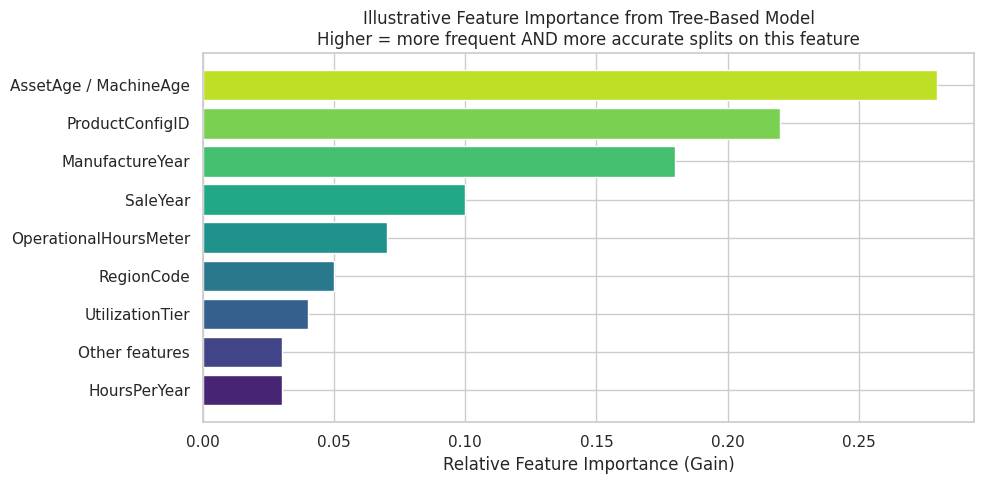


✅ ANSWER: B) The model used that feature frequently to make
   highly accurate splits — it strongly influences predictions.

💡 Insight:
   In our competition: AssetAge/MachineAge has the highest importance
   — machine age is the strongest driver of auction sale price.
   Feature importance guides further feature engineering and selection.


In [16]:
print('=' * 65)
print('  Q14: Feature Importance — What Does High Score Mean?')
print('=' * 65)
print()
print('  How tree-based feature importance is computed:')
print()
print('  For each feature, sum the total GAIN (reduction in impurity/error)')
print('  across ALL splits that used that feature across ALL trees.')
print()
print('  Importance(feature) = sum of gain from all splits using it')
print()
print('  High importance means the feature was BOTH:')
print('  1. Used FREQUENTLY (many decision splits chose this feature)')
print('  2. Produced ACCURATE splits (each split gave a large error reduction)')
print()
print('  What high importance does NOT mean:')
print('  ❌ A) High std deviation — completely unrelated to tree splits')
print('  ❌ C) No missing values — trees with NaN handling work regardless')
print('  ❌ D) High correlation with other features — that is multicollinearity')
print()

# Illustrative feature importance chart (from prior competition work)
fi_example = pd.Series({
    'AssetAge / MachineAge': 0.28,
    'ProductConfigID':        0.22,
    'ManufactureYear':        0.18,
    'SaleYear':               0.10,
    'OperationalHoursMeter':  0.07,
    'RegionCode':             0.05,
    'UtilizationTier':        0.04,
    'HoursPerYear':           0.03,
    'Other features':         0.03,
}).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(fi_example.index, fi_example.values,
        color=sns.color_palette('viridis', len(fi_example)), edgecolor='white')
ax.set_xlabel('Relative Feature Importance (Gain)')
ax.set_title('Illustrative Feature Importance from Tree-Based Model\n'
             'Higher = more frequent AND more accurate splits on this feature')
plt.tight_layout()
plt.show()

print()
print('✅ ANSWER: B) The model used that feature frequently to make')
print('   highly accurate splits — it strongly influences predictions.')
print()
print('💡 Insight:')
print('   In our competition: AssetAge/MachineAge has the highest importance')
print('   — machine age is the strongest driver of auction sale price.')
print('   Feature importance guides further feature engineering and selection.')

  Q15: Primary Benefit of Early Stopping

  How Early Stopping works step by step:
  1. Provide a validation set during training (eval_set)
  2. After each tree/iteration, the model checks validation RMSLE
  3. If validation score does NOT improve for N=stopping_rounds iterations,
     training STOPS automatically
  4. The model weights from the BEST iteration are kept (not the last)



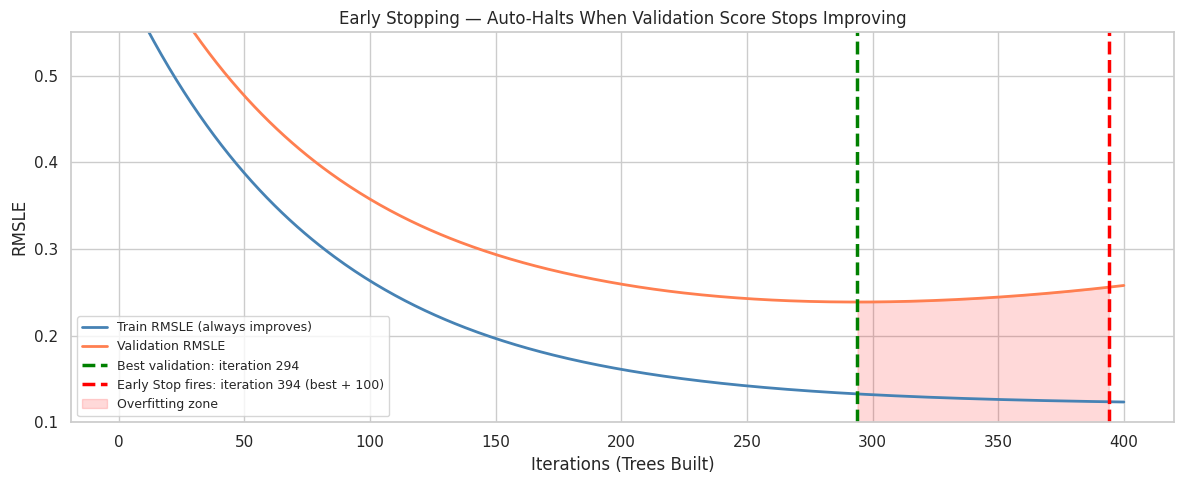


  WITHOUT early stopping: trains all N iters → overfits → worse val RMSLE
  WITH early stopping:    stops 100 rounds after best → optimal generalization

  In our notebook: lgb.early_stopping(50, verbose=False)
  Stops if val RMSLE does not improve for 50 consecutive rounds.

✅ ANSWER: B) Automatically halts training if the validation score
   stops improving, preventing the model from overfitting.

💡 Insight:
   Early stopping gives you TWO benefits for free:
   1. PREVENTS OVERFITTING — keeps the best model, not the most trained
   2. SAVES TIME — no need to guess the perfect n_estimators upfront


In [17]:
print('=' * 70)
print('  Q15: Primary Benefit of Early Stopping')
print('=' * 70)
print()
print('  How Early Stopping works step by step:')
print('  1. Provide a validation set during training (eval_set)')
print('  2. After each tree/iteration, the model checks validation RMSLE')
print('  3. If validation score does NOT improve for N=stopping_rounds iterations,')
print('     training STOPS automatically')
print('  4. The model weights from the BEST iteration are kept (not the last)')
print()

# Simulate training curves to illustrate
iters       = np.arange(1, 401)
train_score = 0.5 * np.exp(-iters / 80) + 0.12
val_score   = (0.48 * np.exp(-iters / 80) + 0.22 +
               3e-7 * (iters - 200).clip(0)**2.2)

best_iter = int(np.argmin(val_score))
stop_iter = min(best_iter + 100, len(iters) - 1)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(iters, train_score, color='steelblue', lw=2, label='Train RMSLE (always improves)')
ax.plot(iters, val_score,   color='coral',     lw=2, label='Validation RMSLE')
ax.axvline(iters[best_iter], color='green', ls='--', lw=2.5,
           label=f'Best validation: iteration {iters[best_iter]}')
ax.axvline(iters[stop_iter], color='red',   ls='--', lw=2.5,
           label=f'Early Stop fires: iteration {iters[stop_iter]} (best + 100)')
ax.fill_between(iters[best_iter:stop_iter+1],
                val_score[best_iter:stop_iter+1],
                alpha=0.15, color='red', label='Overfitting zone')
ax.set_xlabel('Iterations (Trees Built)')
ax.set_ylabel('RMSLE')
ax.set_title('Early Stopping — Auto-Halts When Validation Score Stops Improving')
ax.legend(fontsize=9)
ax.set_ylim(0.10, 0.55)
plt.tight_layout()
plt.show()

print()
print('  WITHOUT early stopping: trains all N iters → overfits → worse val RMSLE')
print('  WITH early stopping:    stops 100 rounds after best → optimal generalization')
print()
print('  In our notebook: lgb.early_stopping(50, verbose=False)')
print('  Stops if val RMSLE does not improve for 50 consecutive rounds.')
print()
print('✅ ANSWER: B) Automatically halts training if the validation score')
print('   stops improving, preventing the model from overfitting.')
print()
print('💡 Insight:')
print('   Early stopping gives you TWO benefits for free:')
print('   1. PREVENTS OVERFITTING — keeps the best model, not the most trained')
print('   2. SAVES TIME — no need to guess the perfect n_estimators upfront')